# Will It Rain Tomorrow? Rainfall Prediction with Weather Data

## Project Summary

This project uses machine learning to predict whether it will rain the next day based on historical weather data. The dataset contains weather information such as temperature, humidity, wind speed, and atmospheric pressure. We will clean and analyze the data, train Logistic Regression and Random Forest models, and compare their performance using evaluation metrics. The project demonstrates how predictive analytics can help identify weather patterns and estimate the likelihood of rainfall.

## Step 1: Import Required Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2: Load the Dataset

In [3]:
df = pd.read_csv("weatherAUS.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (145461, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## Step 3: Explore the Dataset

In [4]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nRainfall distribution:")
print(df["RainTomorrow"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 145461 entries, 0 to 145460
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145461 non-null  str    
 1   Location       145461 non-null  str    
 2   MinTemp        143976 non-null  float64
 3   MaxTemp        144200 non-null  float64
 4   Rainfall       142200 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75626 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135198 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142807 non-null  float64
 14  Humidity3pm    140954 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130433 non-null  float64
 17  Cloud9am       89572 non-null   float64


## Step 4: Visualize Rainfall Data

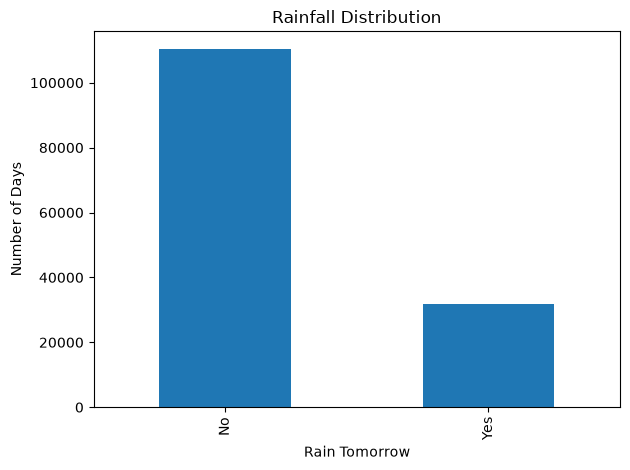

In [5]:
df["RainTomorrow"].value_counts().plot(
    kind="bar",
    title="Rainfall Distribution"
)

plt.xlabel("Rain Tomorrow")
plt.ylabel("Number of Days")
plt.tight_layout()
plt.show()

## Step 5: Clean and Prepare the Data

In [6]:
df = df.drop_duplicates().copy()
df = df.dropna(subset=["RainTomorrow"]).copy()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Month"] = df["Date"].dt.month

df = df.drop(
    columns=["Date", "RISK_MM"],
    errors="ignore"
)

df["RainTomorrow"] = df["RainTomorrow"].map(
    {"No": 0, "Yes": 1}
)

df = df.dropna(subset=["RainTomorrow"])

print("Data cleaned successfully!")
print(df.shape)

Data cleaned successfully!
(142193, 23)


## Step 6: Split the Dataset

In [7]:
X = df.drop(columns=["RainTomorrow"])
y = df["RainTomorrow"].astype(int)

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 113754
Testing samples: 28439


## Step 7: Train the Machine Learning Models

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=6000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(name, "trained successfully!")

d:\Aditya\College\Projects\Public\5th Sem BDA MiniProject\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 6000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=6000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression trained successfully!
Random Forest trained successfully!


## Step 8: Evaluate Model Performance

In [9]:
for name, model in trained_models.items():
    predictions = model.predict(X_test)

    print("\nModel:", name)
    print("Accuracy:", round(
        accuracy_score(y_test, predictions), 4
    ))
    print(classification_report(
        y_test, predictions, zero_division=0
    ))


Model: Logistic Regression
Accuracy: 0.8632
              precision    recall  f1-score   support

           0       0.88      0.95      0.92     22696
           1       0.73      0.51      0.60      5743

    accuracy                           0.86     28439
   macro avg       0.81      0.73      0.76     28439
weighted avg       0.85      0.86      0.85     28439


Model: Random Forest
Accuracy: 0.8552
              precision    recall  f1-score   support

           0       0.91      0.91      0.91     22696
           1       0.64      0.65      0.64      5743

    accuracy                           0.86     28439
   macro avg       0.78      0.78      0.78     28439
weighted avg       0.86      0.86      0.86     28439



## Step 9: Compare the Models

Logistic Regression: 86.32%
Random Forest: 85.52%


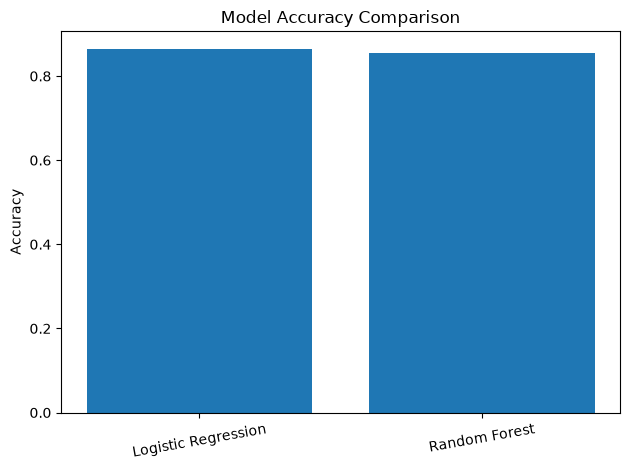

Model Performance Comparison:


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.863,0.733,0.508,0.600
Random Forest,0.855,0.640,0.646,0.643


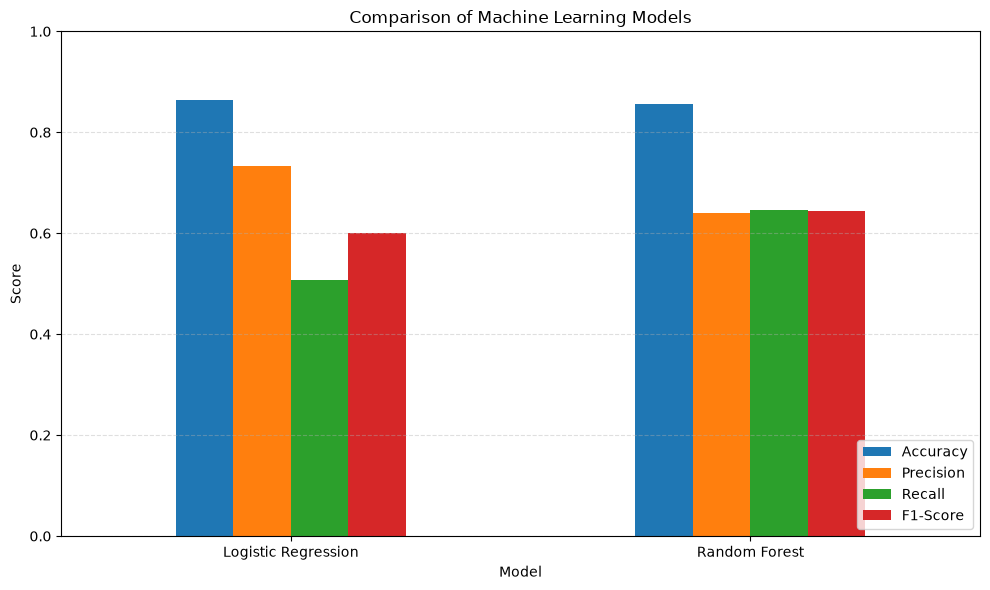

In [10]:
scores = {
    name: accuracy_score(
        y_test, model.predict(X_test)
    )
    for name, model in trained_models.items()
}

for name, score in scores.items():
    print(f"{name}: {score:.2%}")

plt.bar(scores.keys(), scores.values())
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")

print("Model Performance Comparison:")
display(results_df.round(3))

results_df.plot(kind="bar", figsize=(10, 6))
plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Confusion Matrix Analysis

A confusion matrix shows how many predictions were correct and how many were incorrect. It helps us identify rainy days that the models missed and non-rainy days that were incorrectly predicted as rainy.

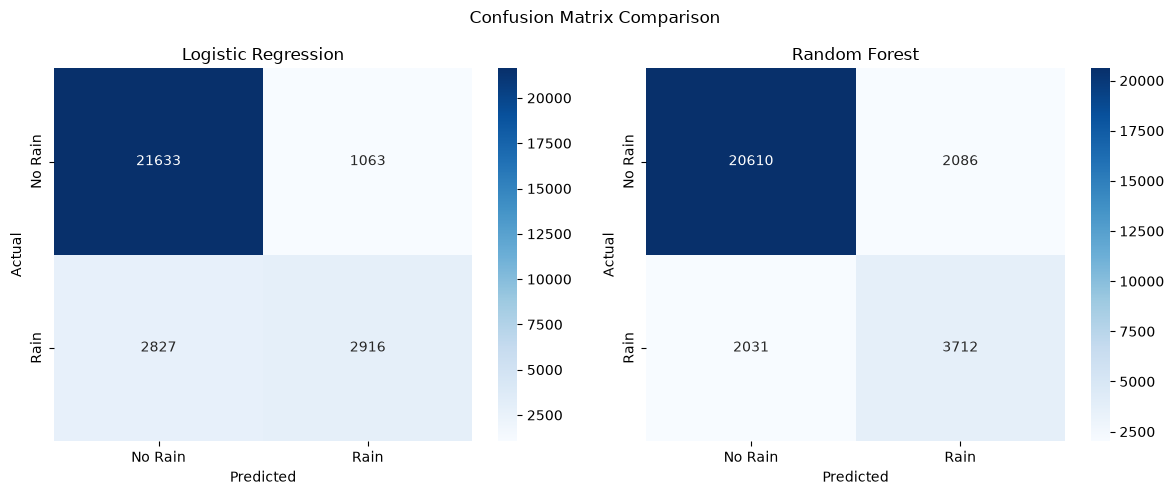

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, trained_models.items()):
    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Rain", "Rain"],
        yticklabels=["No Rain", "Rain"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

## Step 10: Predict Tomorrow's Rainfall (latest row in the CSV)

In [15]:
best_name = max(
    trained_models,
    key=lambda name: classification_report(
        y_test,
        trained_models[name].predict(X_test),
        output_dict=True,
        zero_division=0
    )["1"]["f1-score"]
)

best_model = trained_models[best_name]

latest = pd.read_csv("weatherAUS.csv").tail(1).copy()
latest["Date"] = pd.to_datetime(latest["Date"], errors="coerce")
latest["Month"] = latest["Date"].dt.month

sample = latest.drop(columns=["Date", "RISK_MM", "RainTomorrow"], errors="ignore")[X.columns]
for col in categorical_cols:
    sample[col] = sample[col].astype(object)  

prediction = best_model.predict(sample)[0]
probability = best_model.predict_proba(sample)[0][1]

print("Picked CSV row index:", latest.index[0],
      "| Date:", latest["Date"].dt.strftime("%d %b %Y").iloc[0],
      "| Location:", latest["Location"].iloc[0])
print("sample:")
display(sample)

print("Selected model:", best_name)
print(
    "Prediction:",
    "Rain tomorrow" if prediction == 1 else "No rain tomorrow",
    f"({probability:.0%} chance of rain)"
)


Picked CSV row index: 145463 | Date: 08 Nov 2026 | Location: Sydney
sample:


,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,Month
145463,Sydney,17.5,8.5,47.0,NaN,3.0,NaN,44.0,NaN,NaN,...,65.0,58.0,NaN,1000.5,NaN,6.0,NaN,12.5,Yes,11


Selected model: Random Forest
Prediction: Rain tomorrow (66% chance of rain)


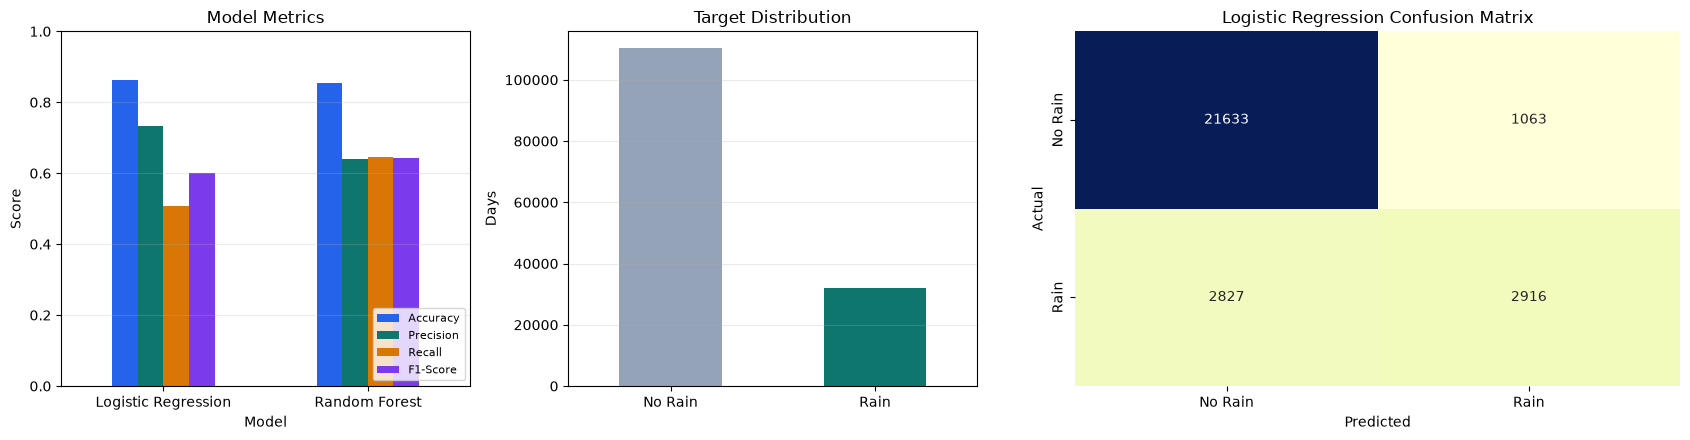

In [13]:
# Interactive-style dashboard summary
from IPython.display import display, HTML

# Build compact KPI cards
best_accuracy = results_df["Accuracy"].max()
best_recall = results_df["Recall"].max()
rain_rate = y.mean()

cards = f"""
<div style="display:flex;gap:12px;flex-wrap:wrap;margin:10px 0 18px 0">
  <div style="background:#0f766e;color:white;padding:14px 20px;border-radius:8px;min-width:150px">
    <div style="font-size:12px;opacity:.85">DATASET ROWS</div><div style="font-size:25px;font-weight:700">{len(df):,}</div>
  </div>
  <div style="background:#2563eb;color:white;padding:14px 20px;border-radius:8px;min-width:150px">
    <div style="font-size:12px;opacity:.85">BEST ACCURACY</div><div style="font-size:25px;font-weight:700">{best_accuracy:.1%}</div>
  </div>
  <div style="background:#d97706;color:white;padding:14px 20px;border-radius:8px;min-width:150px">
    <div style="font-size:12px;opacity:.85">BEST RAIN RECALL</div><div style="font-size:25px;font-weight:700">{best_recall:.1%}</div>
  </div>
  <div style="background:#475569;color:white;padding:14px 20px;border-radius:8px;min-width:150px">
    <div style="font-size:12px;opacity:.85">RAIN TOMORROW RATE</div><div style="font-size:25px;font-weight:700">{rain_rate:.1%}</div>
  </div>
</div>
"""
display(HTML("<h2 style='color:#0f766e'>Rainfall Prediction Dashboard</h2>" + cards))

# Model metrics and confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.15, 1.15, 1.7]})
results_df[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", ax=axes[0], color=["#2563eb", "#0f766e", "#d97706", "#7c3aed"]
)
axes[0].set_title("Model Metrics")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Score")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(axis="y", alpha=.25)

rain_counts = pd.Series({"No Rain": int((y == 0).sum()), "Rain": int((y == 1).sum())})
rain_counts.plot(kind="bar", ax=axes[1], color=["#94a3b8", "#0f766e"])
axes[1].set_title("Target Distribution")
axes[1].set_ylabel("Days")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=.25)

for name, model in trained_models.items():
    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=axes[2],
                xticklabels=["No Rain", "Rain"], yticklabels=["No Rain", "Rain"])
    axes[2].set_title(f"{name} Confusion Matrix")
    axes[2].set_xlabel("Predicted")
    axes[2].set_ylabel("Actual")
    break

plt.tight_layout()
plt.show()

display(HTML(
    f"<div style='padding:12px;background:#ecfdf5;border-left:5px solid #0f766e'>"
    f"<b>Forecast:</b> {best_name} predicts "
    f"<b>{'rain' if prediction == 1 else 'no rain'} tomorrow</b> for the latest row in weatherAUS.csv."
    f"</div>"
))

## Step 11: Conclusion

The project successfully demonstrated how machine learning can be used to predict next-day rainfall using historical weather data. Two classification models, Logistic Regression and Random Forest, were trained and evaluated.

Logistic Regression achieved an accuracy of **86.34%**, while Random Forest achieved **85.52%**. However, Random Forest performed better at identifying rainy days, with a recall of **65%** compared to **51%** for Logistic Regression.

The results show that accuracy alone is not sufficient for evaluating rainfall prediction models. Other metrics, such as precision, recall, and F1-score, are also important, especially when predicting rainy days.

In conclusion, machine learning can help identify weather patterns and estimate the possibility of rainfall based on historical data.